# CircuitEvolve — group-meeting demo

A verifier-first harness for LLM-assisted fault-tolerant (Clifford+T) circuit optimization, compared against
BQSKit-FT under a fixed protocol (TKET-pre-optimized inputs, total algorithmic error ε accounted the BQSKit way).
This notebook runs **offline**: no network and no LLM calls. The one LLM exchange shown is replayed from a cached
record of a real stage-1 run (`notebooks/demo_assets/`, extracted by `demo_assets/make_demo_assets.py`); everything
else — verifier, metric, refit — runs live. Every number printed is computed here or read from `results/`.

Run: *Restart & Run All* with the repo venv kernel (about 3 s), or
`.venv/bin/python -m jupyter nbconvert --to notebook --execute --inplace notebooks/group_meeting_demo.ipynb`; where a
sandbox forbids kernel sockets, `.venv/bin/python notebooks/demo_assets/run_inprocess.py notebooks/group_meeting_demo.ipynb`
executes the same cells in-process (that is how the saved outputs were produced).

In [1]:
import json, re, sys, time
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

import matplotlib
matplotlib.use("Agg")
matplotlib.rcParams.update({"font.size": 7, "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "axes.spines.top": False, "axes.spines.right": False})
T0 = time.time()

import io
def show_fig(fig):
    """Render a matplotlib figure as an embedded PNG (works without an inline backend)."""
    import matplotlib.pyplot as _plt
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=150, bbox_inches="tight"); _plt.close(fig)
    display(Image(data=buf.getvalue()))
ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
ASSETS = ROOT / "notebooks" / "demo_assets"
S1 = ROOT / "results" / "window_runs" / "stage1"
BASE = ROOT / "results" / "bqskit_baselines" / "stage1"
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120); pd.set_option("display.max_columns", 30)
REC = json.loads((ASSETS / "qpe_8_e3_records.json").read_text())
PB = json.loads((ASSETS / "playbook_stage1.json").read_text())
print("repo:", ROOT)
print("cached records from:", REC["source"], "sha1", REC["source_sha1"][:12])

repo: /Users/shubdeepmohapatra/Documents/CircuitEvolve
cached records from: results/window_runs/stage1/stage1_qpe_8_e3.jsonl sha1 f8927916a58b


## 1. The idea: mutator → verifier → metric, inside a simple selection loop

The LLM is only a **mutation operator**: it sees one small window of the circuit and proposes a replacement.
An exact/numerical **verifier** that the search cannot modify decides whether the replacement is admissible, and a
**metric** with BQSKit's error convention decides whether it is better. A **playbook** of LLM-written hints evolves
between calls, but it can only change proposals, never acceptance.

| Part | Module (`circuitevolve/`) | Role |
|---|---|---|
| circuit + windows | `core/circuit.py` | TKET input, QASM I/O, windows ≤ 4 qubits / ≤ 40 ops (BQSKit QuickPartitioner), `splice` |
| **mutator** | `core/mutator.py` (+ `core/refit.py`) | prompt for one window; parses ```` ```window ```` (exact rewrite) and ```` ```fix ```` (fix-and-refit) blocks with regexes, never `eval` |
| **verifier** | `core/verifier.py` → frozen `blocks/verify_block.py` | exact D[ω] check for Clifford+T windows, else operator distance ≤ allowance; whole circuit vs the original |
| **metric** | `core/metric.py` | T-count: remaining Rz via gridsynth at ε_rz = ε_synth / N_Rz, π/4 multiples exact |
| error ledger | `core/ledger.py` | splits ε between window rewrites (measured distances) and final synthesis; bound ≤ ε |
| **selection** | `core/loop.py` | archive (best + 3), windows by T-cost, accept on measured improvement, one log line per LLM call |
| **playbook** | `search/playbook.py` | reflector-written rules, A/B-gated: promoted only on measured T reductions |

The cell below imports each part and checks that the frozen verifier files are byte-identical to the ones the
stage-1 run recorded.

In [2]:
import circuitevolve.core.circuit as c_circuit, circuitevolve.core.mutator as c_mutator, circuitevolve.core.refit as c_refit
import circuitevolve.core.verifier as c_verifier, circuitevolve.core.metric as c_metric, circuitevolve.core.ledger as c_ledger
import circuitevolve.core.loop as c_loop, circuitevolve.search.playbook as c_playbook
from circuitevolve.integrity import FROZEN, frozen_digest

for mod in (c_circuit, c_mutator, c_refit, c_verifier, c_metric, c_ledger, c_loop, c_playbook):
    print(f"{mod.__name__:34s} {mod.__doc__.strip().splitlines()[0][:100]}")
now, logged = frozen_digest()[:16], REC["start"]["verifier_digest"]
print("\nfrozen files:", ", ".join(FROZEN))
print("verifier digest now:", now, "| recorded by the stage-1 qpe_8 run:", logged)
assert now == logged, "frozen verifier changed since the stage-1 run"

circuitevolve.core.circuit         Clifford+Rz circuit object, QASM in/out, stage-1 inputs and windows.
circuitevolve.core.mutator         LLM window mutator: prompt construction and LITERAL parsing of replacement windows.
circuitevolve.core.refit           Fix-and-refit: the LLM names rotations of a window and target values; the toolbox re-instantiates th
circuitevolve.core.verifier        Verifier for window replacements and whole circuits - a thin wrapper around the FROZEN
circuitevolve.core.metric          T-count under BQSKit's error convention (plus rotation and CNOT counts).
circuitevolve.core.ledger          Error ledger: one total algorithmic error eps per circuit.
circuitevolve.core.loop            Simple selection loop: mutator -> verifier -> metric, with a small archive and a self-evolving playb
circuitevolve.search.playbook      Self-evolving rule file ("playbook") for the LLM proposer.

frozen files: ir.py, ring.py, sim.py, spec.py, verify.py, cost.py, acceptance.py, bloc

## 2. A stage-1 circuit and its T-count under the BQSKit convention

`qpe_8` after TKET `FullPeepholeOptimise` is the shared input of every arm. Under BQSKit's convention every
rotation that is not a multiple of π/4 is synthesized by gridsynth at ε_rz = ε / N_Rz; π/4 multiples are exact
(odd multiples cost one T). With the whole ε = 1e-3 given to synthesis, our metric module must reproduce the
B0 (TKET + gridsynth) number in the baselines table exactly — the cell asserts it.

In [3]:
from circuitevolve.core.circuit import load_input, original_ops, windows, splice, window_text
from circuitevolve.core.metric import BqskitTMetric, improves

EPS = 1e-3
circ = load_input("qpe_8")
cost0 = BqskitTMetric(EPS).cost(circ.ops)
base = pd.read_csv(BASE / "stage1_baselines_v2.csv")
b0 = int(base.query("circuit == 'qpe_8' and eps_total == @EPS and arm == 'B0'").t_count_canon.iloc[0])
ws, flat = windows(circ)
print("input:", circ.meta["source"])
print(f"qubits {circ.n} | ops {len(circ.ops)} | rotations to synthesize N_Rz = {cost0['rz']} | explicit T {cost0['t_fixed']} "
      f"| CNOT {cost0['cx']} | windows {len(ws)}")
print(f"eps_rz = eps / N_Rz = {cost0['eps_rz']:.4e}")
print(f"T-count = {cost0['t_fixed']} (explicit T) + {cost0['t_gs']} (gridsynth) = {cost0['t']}   | B0 t_count_canon = {b0}")
assert cost0["t"] == b0

input: results/bqskit_baselines/stage1/inputs/qpe_8_tket.qasm
qubits 8 | ops 1034 | rotations to synthesize N_Rz = 257 | explicit T 157 | CNOT 268 | windows 30
eps_rz = eps / N_Rz = 3.8911e-06
T-count = 157 (explicit T) + 14604 (gridsynth) = 14761   | B0 t_count_canon = 14761


## 3. Baselines at total error 1e-3

Canonical T-counts (pygridsynth recount) from `results/bqskit_baselines/stage1/stage1_baselines_v2.csv`:
**B0** TKET + gridsynth, **B1** pyzx `full_reduce` + gridsynth, **B2** default BQSKit-FT (the paper's
"Baseline"), **B3** the published Dyadic Phase Fixing script `alg_err_workflow.py` (flagged ⚑: its code-accounted
error bound exceeds ε), and **B3g**, its DPF stage followed directly by gridsynth, bounded by ε. "best valid" is the
lowest of B0, B1, B2, B3g — the bar used in the results section.

In [4]:
CIRCS = ["qft_8", "qpe_8", "qae_13", "heisenberg_6", "tfim_6", "hubbard_8", "qml_13", "hhl_8"]
b = base[base.eps_total == EPS]
tab = b.pivot(index="circuit", columns="arm", values="t_count_canon").loc[CIRCS, ["B0", "B1", "B2", "B3", "B3g"]].astype(int)
over = b[b.arm == "B3"].set_index("circuit").bound_over_eps.loc[CIRCS]
qubits = b.drop_duplicates("circuit").set_index("circuit").qubits.loc[CIRCS]
valid = tab[["B0", "B1", "B2", "B3g"]]
show = pd.DataFrame({"qubits": qubits, "B0": tab.B0, "B1": tab.B1, "B2": tab.B2,
                     "B3 ⚑ (bound/ε)": [f"{t} ⚑ ({o:.3g}x ε)" for t, o in zip(tab.B3, over)], "B3g": tab.B3g,
                     "best valid": valid.min(axis=1),
                     "arm": [("=".join(a for a in valid.columns if r[a] == r.min())) for _, r in valid.iterrows()],
                     "B1 vs B0 %": (100 * (tab.B1 / tab.B0 - 1)).round(1)})
print("B3 bound / eps at 1e-3 (all circuits):", sorted({round(float(o), 3) for o in over}),
      "| B0 == B2 on every circuit:", bool((tab.B0 == tab.B2).all()))
display(show)

B3 bound / eps at 1e-3 (all circuits): [1.7] | B0 == B2 on every circuit: True


,qubits,B0,B1,B2,B3 ⚑ (bound/ε),B3g,best valid,arm,B1 vs B0 %
circuit,,,,,,,,,
qft_8,8,2391,1577,2391,2226 ⚑ (1.7x ε),2029,1577,B1,-34.0
qpe_8,8,14761,11485,14761,39565 ⚑ (1.7x ε),8020,8020,B3g,-22.2
qae_13,13,7821,4527,7821,7516 ⚑ (1.7x ε),6909,4527,B1,-42.1
heisenberg_6,6,8200,8200,8200,10128 ⚑ (1.7x ε),8600,8200,B0=B1=B2,0.0
tfim_6,6,8560,8560,8560,12990 ⚑ (1.7x ε),9600,8560,B0=B1=B2,0.0
hubbard_8,8,4312,4312,4312,7588 ⚑ (1.7x ε),4712,4312,B0=B1=B2,0.0
qml_13,13,6326,6326,6326,7668 ⚑ (1.7x ε),6790,6326,B0=B1=B2,0.0
hhl_8,8,35450,29205,35450,93637 ⚑ (1.7x ε),19443,19443,B3g,-17.6


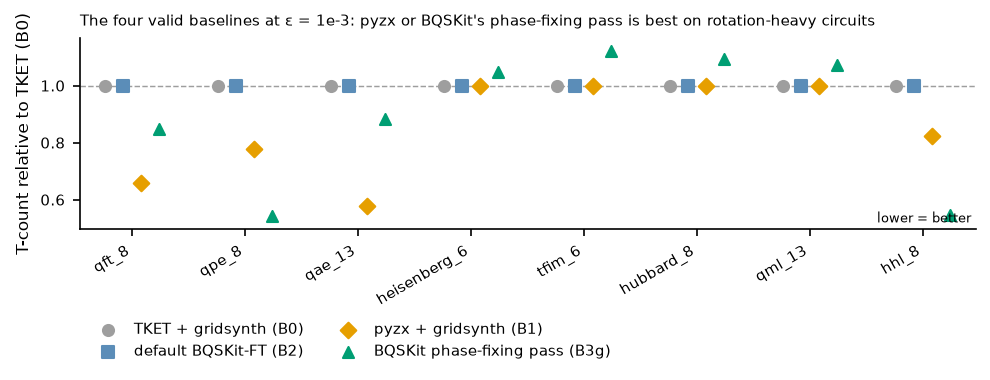

In [5]:
import matplotlib.pyplot as plt, numpy as np
ser4 = [("B0", "TKET + gridsynth (B0)", "#9e9e9e", "o"), ("B2", "default BQSKit-FT (B2)", "#5b8db8", "s"),
        ("B1", "pyzx + gridsynth (B1)", "#e69f00", "D"), ("B3g", "BQSKit phase-fixing pass (B3g)", "#009e73", "^")]
r4 = valid.div(valid.B0, axis=0)
xx = np.arange(len(CIRCS)); off = np.linspace(-0.24, 0.24, len(ser4))
fig, ax = plt.subplots(figsize=(6.6, 3.0))
for (c, lab, col, m), o in zip(ser4, off):
    ax.scatter(xx + o, r4.loc[CIRCS, c], color=col, marker=m, s=28, label=lab, zorder=3)
ax.axhline(1.0, color="#9e9e9e", lw=0.7, ls="--")
ax.set_xticks(xx); ax.set_xticklabels(CIRCS, rotation=30, ha="right")
ax.set_ylabel("T-count relative to TKET (B0)")
ax.set_title("The four valid baselines at ε = 1e-3: pyzx or BQSKit's phase-fixing pass is best on rotation-heavy circuits",
             loc="left", fontsize=7)
ax.text(0.995, 0.02, "lower = better", transform=ax.transAxes, ha="right", va="bottom", fontsize=6)
ax.legend(frameon=False, ncol=2, fontsize=7, loc="upper left", bbox_to_anchor=(0, -0.42))
ax.margins(x=0.03, y=0.08); fig.tight_layout(); show_fig(fig)


## 4. One LLM mutation, replayed from the cache

**4a — the cached exchange.** In the stage-1 `qpe_8` run at ε = 1e-3 the model was shown a 4-qubit, 40-op window
of the input circuit with, per rotation, its angle, its gridsynth T-cost and its Pauli frame P (the rotation's Pauli
after moving all Clifford gates to the end of the window). It answered with a one-line **fix-and-refit**: delete
one rotation and let the toolbox re-fit the others. Below: the window as recomputed now (checked to be the one in the
cached prompt), an excerpt of the prompt, and the model's response.

In [6]:
from circuitevolve.core.mutator import extract_proposals, parse_window, indexed_window_text, rotation_paulis
acc, start = REC["accepted"], REC["start"]
w = ws[acc["window"]["index"]]
assert indexed_window_text(w.ops) in acc["prompt"], "window differs from the cached prompt"
print(f"call {acc['call']} | window {w.index} on global qubits {w.qubits} | {len(w.ops)} ops | "
      f"window T-cost {acc['window']['t_cost']} | allowance {acc['allowance']:.3e}\n")
lines = acc["prompt"].splitlines()
keep = [l for l in lines if l.lstrip().startswith(("* every other rz", "between the original", "op 12 on", "op 19 on",
                                                    "op 39 on", "Window T-cost"))]
print("PROMPT EXCERPT (%d of %d lines):" % (len(keep), len(lines)))
print("\n".join("  " + l.strip() for l in keep))
print("\nRESPONSE (verbatim, cached):\n" + acc["response"])

call 4 | window 17 on global qubits (3, 5, 6, 7) | 40 ops | window T-cost 686 | allowance 6.250e-05

PROMPT EXCERPT (6 of 100 lines):
  * every other rz is synthesized by gridsynth at eps_rz = 3.891e-06, costing about 3*log2(1/eps_rz) T
  between the original and the replacement window <= allowance = 6.250e-05. Clifford+T windows are checked exactly.
  op 12 on q2: rz(-0.7279362058) | -1*pi/4 | 5.746e-02 | 2.873e-02 | 58 | P=+IIZI
  op 19 on q2: rz(1.611480107) | 2*pi/4 | 4.068e-02 | 2.034e-02 | 58 | P=+IIZI
  op 39 on q2: rz(-0.100122238) | 0*pi/4 | 1.001e-01 | 5.006e-02 | 56 | P=+IIZI
  Window T-cost now: 686 T (12 rotation(s) to synthesize, 4 explicit T).

RESPONSE (verbatim, cached):
Looking at the P-labels, I can find merge candidates:

- op 1 (ZIII) and op 15 (ZIII): same P, nothing non-commuting with ZIII of the opposite parity in between that blocks it... need to check commutation of everything between them. But let's check the easier ones first.
- op 12 (IIZI), op 19 (IIZI), o

**4b — parse, refit, verify, measure (all live).** The response is parsed with regexes only. The refit
(BQSKit instantiation) re-fits the window's remaining angles; the frozen verifier measures the phase-aligned operator
distance against the ledger's allowance; the metric prices the spliced circuit at the ε_rz of its own ledger; and the
whole circuit is checked against the original qseed circuit. Each live value is asserted equal to the cached log.

In [7]:
from circuitevolve.core.refit import refit
from circuitevolve.core.verifier import verify_window, check_circuit
from circuitevolve.core.ledger import Ledger
from circuitevolve.blocks.cost_model import rz_angles

props, perr = extract_proposals(acc["response"])
action, fixes = props[0]
print("parsed:", props, "| parse errors:", perr)
rf = refit(w.ops, w.k, fixes, multistarts=8, seed=acc["call"])           # same seed as the run
ledger0 = Ledger(EPS).with_input(start["ledger"]["d_input"])              # d_input measured at run start
v = verify_window(w.ops, rf["ops"], w.k, ledger0.allowance())
print(f"refit: free angles {rf['n_free']}, fit distance {rf['dist']:.2e}")
print(f"verifier: ok={v['ok']} mode={v['mode']} distance={v['dist']:.2e} <= allowance {v['allowance']:.2e} -> charge {v['charge']:.2e}")

metric = BqskitTMetric(EPS)
def priced(ops, led):                       # T at eps_rz = eps_synth(ledger) / N_Rz, as in the loop
    return metric.cost(ops, eps_rz=led.eps_synth / len(rz_angles(ops)))
ledger1 = ledger0.charge(v["charge"])
new_ops = splice(flat, w, rf["ops"])
before, after = priced(flat, ledger0), priced(new_ops, ledger1)
orig, n = original_ops("qpe_8")
whole = check_circuit(orig, new_ops, n, bound=ledger1.d_input + ledger1.spent)
ba = pd.DataFrame([{k: before[k] for k in ("t", "rz", "cx", "eps_rz")}, {k: after[k] for k in ("t", "rz", "cx", "eps_rz")}],
                  index=["before", "after"])
print(ba.to_string(formatters={"eps_rz": "{:.6e}".format}))
print(f"metric.improves: {improves(after, before)} | ΔT = {after['t'] - before['t']} | "
      f"whole-circuit check ({whole['method']}): dist {whole['dist']:.2e} <= bound {whole['bound']:.2e} -> {whole['ok']}")
cand = acc["candidates"][0]
assert window_text(rf["ops"]) == cand["window"] and v["dist"] == cand["verify"]["dist"]
assert (before["t"], after["t"]) == (acc["t_before"], acc["t_after"]) and whole["ok"]
print("live replay == cached log (window, distance, T before/after)")

parsed: [('fix', {19: 0.0})] | parse errors: []
refit: free angles 11, fit distance 5.99e-16
verifier: ok=True mode=approx distance=1.45e-15 <= allowance 6.25e-05 -> charge 1.45e-15
            t   rz   cx       eps_rz
before  14761  257  268 3.891051e-06
after   14705  256  268 3.905296e-06
metric.improves: True | ΔT = -56 | whole-circuit check (unitary): dist 9.30e-14 <= bound 9.41e-14 -> True
live replay == cached log (window, distance, T before/after)


**4c — a rejected cached proposal.** Later in the same run (on a different parent circuit) the model again claimed a
same-P merge and proposed deleting one rotation. The refit could not absorb it and the verifier rejected it. The
Pauli frames computed live show why: a rotation between the two equal-P rotations anticommutes with them, so they do
not merge.

In [8]:
rej = REC["rejected"]
k_r = len(rej["window"]["qubits"])
rops = parse_window(re.search(r"```window\n(.*?)```", rej["prompt"], re.S).group(1))   # window as shown to the model
rprops, _ = extract_proposals(rej["response"])
rfix = rprops[0][1]
print(f"call {rej['call']} | window {rej['window']['index']} on {rej['window']['qubits']} | proposal: {rprops}")
said = [l for l in rej["response"].split("```fix")[0].splitlines() if l.strip()]
print("model's reasoning (last lines, verbatim):\n  " + "\n  ".join(l[:160] for l in said[-3:]))
rf2 = refit(rops, k_r, rfix, multistarts=8, seed=rej["call"])
v2 = verify_window(rops, rf2["ops"], k_r, rej["allowance"])
print(f"\nverifier: ok={v2['ok']} | reason: {v2['reason']}   (cached: {rej['candidates'][0]['verify']['reason']})")
assert not v2["ok"] and v2["reason"] == rej["candidates"][0]["verify"]["reason"]

P = rotation_paulis(rops, k_r)
def commute(p, q):                          # Paulis commute iff they differ (both non-I) on an even number of qubits
    return sum(a != "I" and b != "I" and a != b for a, b in zip(p[1:], q[1:])) % 2 == 0
(i,) = rfix
partners = [j for j in P if j != i and P[j][1:] == P[i][1:]]
for j in partners:
    lo, hi = sorted((i, j))
    block = [(m, P[m]) for m in P if lo < m < hi and not commute(P[m], P[i])]
    print(f"op {i} P={P[i]} vs op {j} P={P[j]}: rotations in between that anticommute: {block or 'none'}")

call 18 | window 27 on [3, 5, 6, 7] | proposal: [('fix', {23: 0.0})]
model's reasoning (last lines, verbatim):
  **op 0, 23, 30 (P=+IIZI on q2):** Need to check commutation of everything between them. Between op0 and op23 we have ops on q3/q0/q1 mixing in cx q0 q2 twice — 
  Also op0 (+IIZI) sits far earlier but separated by cx q0 q2 (acts on q2) which doesn't commute with Z on q2's identity structure trivially — IIZI vs cx q0q2: cx
  Try merging op23 -> op30.

verifier: ok=False | reason: distance 1.173e-01 > allowance 6.250e-05   (cached: distance 1.173e-01 > allowance 6.250e-05)
op 23 P=+IIZI vs op 0 P=+IIZI: rotations in between that anticommute: [(19, '-ZIXI')]
op 23 P=+IIZI vs op 30 P=+IIZI: rotations in between that anticommute: [(27, '+IIXI')]


**4d — a planted bad rewrite, rejected live.** Take the accepted refitted window from 4b and flip the sign of the
merged rotation's angle — a typical sign slip in a hand derivation. It has the same T-cost, so only the verifier
stands between it and the circuit.

In [9]:
good = rf["ops"]
j = max(m for m, (g, _, _) in enumerate(good) if g == "rz")             # the rotation that absorbed the deleted one
bad = list(good); g_, qs_, a_ = bad[j]; bad[j] = (g_, qs_, -a_)
v3 = verify_window(w.ops, bad, w.k, ledger0.allowance())
print(f"planted: op {j} rz({a_:.6f}) -> rz({-a_:.6f}) on local q{qs_[0]}")
print(f"T-cost unchanged: {priced(splice(flat, w, bad), ledger1)['t'] == after['t']} | verifier: ok={v3['ok']} | {v3['reason']}")
assert not v3["ok"]

planted: op 38 rz(1.511358) -> rz(-1.511358) on local q2
T-cost unchanged: True | verifier: ok=False | distance 1.372e+00 > allowance 6.250e-05


## 5. The playbook learned in stage 1

A reflector call (every 10 proposer calls) reads recent verifier outcomes and proposes short rules. Each rule is
A/B-tested: shown in some prompts and hidden in others; it is promoted to *active* only if prompts that showed it
led to more **accepted, T-reducing** proposals, and retired if not. The playbook started empty and was carried
across the stage-1 runs in a fixed order. Below: the active rules with their evidence, and the status counts after
each run.

In [10]:
rules = pd.DataFrame(PB["rules"])
active = rules[rules.status == "active"]
for _, r in active.iterrows():
    print(f"{r.id}: {r.text[:150]}{'...' if len(r.text) > 150 else ''}")
    print(f"     shown {r.exposures} prompts | improving prompts: shown {r.with_improvements}/{r.with_prompts} vs hidden "
          f"{r.without_improvements}/{r.without_prompts} | verifier passes: shown {r.with_pass}/{r.with_props} vs hidden "
          f"{r.without_pass}/{r.without_props} | {r.note}")
cnt = rules.status.value_counts()
print(f"\nproposed by the reflector: {len(rules)} (origin: {', '.join(f'{k} {int(v)}' for k, v in rules.origin.value_counts().items())}) | "
      f"active {cnt.get('active', 0)}, candidate {cnt.get('candidate', 0)}, retired {cnt.get('retired', 0)}")
print("active rules mentioning the Pauli-frame merge criterion:",
      int(active.text.str.contains(r"Pauli|\bP=|same P", regex=True).sum()))
display(pd.DataFrame(PB["timeline"]).set_index("run").rename_axis("after run"))

R36: Before proposing 'op N->0' (deleting an rz), check that op N's angle is already near 0 or 2*pi*k in the ORIGINAL unitary at that point in the circuit ...
     shown 144 prompts | improving prompts: shown 6/10 vs hidden 2/10 | verifier passes: shown 6/8 vs hidden 2/5 | (z = +1.83 at call 32)
R38: Batching 3+ 'op N->0' deletions fails even when individually each looked plausible (distance 0.18-0.61 observed for 3-6 op batches). Cap batched rz de...
     shown 132 prompts | improving prompts: shown 5/8 vs hidden 2/12 | verifier passes: shown 5/7 vs hidden 2/5 | (z = +2.12 at call 43)
R41: Batched 'op N->0' deletions across 5 unrelated indices (e.g. ops 4,11,13,21,30) fail with distance ~0.1-0.2, confirming batching risk extends beyond s...
     shown 128 prompts | improving prompts: shown 4/9 vs hidden 0/6 | verifier passes: shown 4/5 vs hidden 0/2 | (z = +1.82 at call 5)

proposed by the reflector: 63 (origin: reflector 63) | active 3, candidate 8, retired 52
active rules mentioning

,n_rules,active,candidate,retired
after run,,,,
qft_8_e3,5,0,5,0
qpe_8_e3,16,0,14,2
qae_13_e3,24,0,17,7
heisenberg_6_e3,27,0,11,16
tfim_6_e3,30,0,5,25
hubbard_8_e3,34,0,6,28
qml_13_e3,34,0,4,30
hhl_8_e3,46,2,10,34
qpe_8_e5,52,3,10,39


<!-- ablation_v1 section -->
## 6. Does the shared playbook help? (train / freeze / test)

The stage-1 playbook in section 5 was learned and used on the same circuits, so it cannot show that its rules
transfer. This experiment separates learning from testing: a fresh, empty playbook is learned on **development**
circuits only (smaller members of the qft / qpe / qae families), then **frozen** and hashed, then **tested** on
held-out circuits in three arms: no playbook, the frozen learned playbook, and a placebo playbook holding one
hand-written generic rule of similar length that is rendered into the prompt by the same code path. Every arm gets
the same number of proposer calls per run and no reflector calls, so the playbook block is the only difference
in the prompt. The design parameters below are read from the run files in `results/window_runs/ablation_v1/`.

In [11]:
import hashlib
from circuitevolve.search.playbook import Playbook

AB = ROOT / "results" / "window_runs" / "ablation_v1"
PBDIR = ROOT / "playbooks"
abl = pd.read_csv(AB / "ablation_results.csv")
dev_prog = [json.loads(l) for l in (AB / "_dev_progress.jsonl").read_text().splitlines() if l.strip()]
frozen_sha = {name: sha for sha, name in (l.split() for l in (AB / "FROZEN.sha256").read_text().splitlines() if l.strip())}
sha_ok = {name: hashlib.sha256((PBDIR / name).read_bytes()).hexdigest() == sha for name, sha in frozen_sha.items()}
assert all(sha_ok.values()), f"playbook file changed after freezing: {sha_ok}"

dev_names = [r["name"] for r in dev_prog]
dev_prop = sum(r["stats"]["proposal_calls"] for r in dev_prog); dev_refl = sum(r["stats"]["reflect_calls"] for r in dev_prog)
dev_tok = sum(r["tokens"]["input"] + r["tokens"]["output"] for r in dev_prog)
ho = list(dict.fromkeys(abl.circuit)); arms = list(dict.fromkeys(abl.arm)); seeds = sorted(abl.seed.unique())
dev_eps = sorted({json.loads((AB / f"{r['tag']}_summary.json").read_text())["eps"] for r in dev_prog})
ho_eps = sorted({json.loads((AB / f"{t}_summary.json").read_text())["eps"] for t in abl.tag})
calls = sorted(abl.proposal_calls.unique()); assert int(abl.reflect_calls.sum()) == 0
assert abl[abl.arm == "learned"].playbook_sha256.eq(frozen_sha["dev_v1.json"]).all()
assert abl[abl.arm == "placebo"].playbook_sha256.eq(frozen_sha["placebo_v1.json"]).all()
display(Markdown("\n".join([
    f"* **Train** (development only): {', '.join(dev_names)} — {dev_prop} proposer + {dev_refl} reflector calls, "
    f"{dev_tok:,} tokens, eps_total {', '.join(f'{e:g}' for e in dev_eps)}.",
    f"* **Freeze**: " + "; ".join(f"`playbooks/{n}` SHA-256 `{s}` (file re-hashed now: {'match' if sha_ok[n] else 'MISMATCH'})"
                                  for n, s in frozen_sha.items()),
    f"* **Test** (held out): {', '.join(ho)} x arms {', '.join(arms)} x seeds {', '.join(map(str, seeds))}; "
    f"{'/'.join(map(str, calls))} proposer calls per run, reflector calls in all arms: {int(abl.reflect_calls.sum())}; "
    f"eps_total {', '.join(f'{e:g}' for e in ho_eps)}; model {', '.join(abl.model.unique())}.",
])))
dev_tab = pd.DataFrame([{"dev circuit": r["name"], "n": r["n"], "T start (=B0)": r["t_before"], "T end": r["t_after"],
                         "proposer": r["stats"]["proposal_calls"], "reflector": r["stats"]["reflect_calls"],
                         "accepted": r["stats"]["accepted"], "rules live after": r["playbook"]["live"],
                         "active after": r["playbook"]["active"]} for r in dev_prog]).set_index("dev circuit")
display(dev_tab)

* **Train** (development only): qft_4, qft_5, qft_6, qft_7, qpe_6, qae_11, qae_15 — 219 proposer + 12 reflector calls, 685,358 tokens, eps_total 0.001.
* **Freeze**: `playbooks/dev_v1.json` SHA-256 `6e6b65fa4e40596ad8dce14ff49e93759126853546c60a159bded02d0b9004f5` (file re-hashed now: match); `playbooks/placebo_v1.json` SHA-256 `27162b1933a1aaad9b7ffb2401a0ca26a41d9fd9ff22da6429e19a84c0bdbffb` (file re-hashed now: match)
* **Test** (held out): qft_8, qpe_8, qae_13, hhl_8 x arms none, learned, placebo x seeds 0, 1; 20 proposer calls per run, reflector calls in all arms: 0; eps_total 0.001; model claude-sonnet-5.

,n,T start (=B0),T end,proposer,reflector,accepted,rules live after,active after
dev circuit,,,,,,,,
qft_4,4,343,299,31,2,1,5,0
qft_5,5,669,619,31,2,1,9,0
qft_6,6,1133,1081,33,0,1,7,0
qft_7,7,1695,1645,32,1,1,7,1
qpe_6,6,8027,7919,31,2,1,8,1
qae_11,11,5219,5127,30,3,1,13,1
qae_15,15,10823,10823,31,2,0,12,1


**6a — the frozen rules.** The learned arm sees only ACTIVE rules; the top candidate rules by evidence (z of improving-prompt rates, shown vs hidden) are listed to show what nearly made it. The placebo rule is the control.

In [12]:
import textwrap
dev_pb = Playbook.load(PBDIR / "dev_v1.json", frozen=True)
plc_pb = Playbook.load(PBDIR / "placebo_v1.json", frozen=True)
zf = lambda r: Playbook.z_score(r, "improvement")
st = pd.Series([r.status for r in dev_pb.rules]).value_counts()
print(f"dev_v1: {len(dev_pb.rules)} rules proposed by the reflector -> active {st.get('active', 0)}, "
      f"candidate {st.get('candidate', 0)}, retired {st.get('retired', 0)} | promote at z >= {dev_pb.z_promote} "
      f"with >= {dev_pb.min_pass_with} improving prompts | frozen mode shows ACTIVE rules only\n")
act = [r for r in dev_pb.rules if r.status == "active"]
cand = sorted((r for r in dev_pb.rules if r.status == "candidate"), key=zf, reverse=True)[:3]
rows = []
for label, rs in (("ACTIVE (shown in the learned arm)", act), ("top-3 CANDIDATE (never shown when frozen)", cand),
                  ("PLACEBO (shown in the placebo arm)", [r for r in plc_pb.rules if r.status == "active"])):
    print(f"--- {label}")
    for r in rs:
        print(textwrap.fill(f"{r.id} [{r.status}] {r.text}", 116, subsequent_indent="    "))
        print(f"    evidence: improving prompts shown {r.with_improvements}/{r.with_prompts} vs hidden "
              f"{r.without_improvements}/{r.without_prompts}; z(now) = {zf(r):+.2f} {r.note}".rstrip())
        rows.append({"rule": r.id, "group": label.split(" (")[0], "chars": len(r.text), "shown improving": r.with_improvements,
                     "shown prompts": r.with_prompts, "hidden improving": r.without_improvements,
                     "hidden prompts": r.without_prompts, "z(now)": round(zf(r), 2)})
display(pd.DataFrame(rows).set_index("rule"))

dev_v1: 28 rules proposed by the reflector -> active 1, candidate 11, retired 16 | promote at z >= 1.64 with >= 3 improving prompts | frozen mode shows ACTIVE rules only

--- ACTIVE (shown in the learned arm)
R3 [active] A 'fix' proposal that removes a single rz without compensating for the Clifford gates around it on the
    same qubit will fail the operator-norm verifier; track the full Pauli-frame/basis change across the window
    before deleting or merging any rotation gate.
    evidence: improving prompts shown 3/37 vs hidden 0/53; z(now) = +1.65 (z = +1.65 at call 5)
--- top-3 CANDIDATE (never shown when frozen)
R16 [candidate] A near-miss rejection like 'op 24->0: distance 2.330e-04' (just above allowance 6.250e-05) often
    means the rotation is nearly but not exactly conjugate to identity -- do not round small residual angles to
    exactly 0; keep the residual rz or fold it into the adjacent Clifford's exact phase instead of truncating.
    evidence: improving prompts shown

,group,chars,shown improving,shown prompts,hidden improving,hidden prompts,z(now)
rule,,,,,,,
R3,ACTIVE,255,3,37,0,53,1.65
R16,top-3 CANDIDATE,311,1,35,0,35,0.60
R23,top-3 CANDIDATE,306,0,9,0,22,0.53
R28,top-3 CANDIDATE,383,0,0,0,1,0.45
R1,PLACEBO,292,0,0,0,0,0.00


**6b — the same prompt with and without the playbook block.** From the held-out logs: the same circuit, seed and
call number, the same parent circuit and window, in the no-playbook and learned arms. In the first batch both arms
see identical prompts except for the inserted rule block (checked below with a character diff). The pair shown was
picked because the verdicts differ; the tally over all such matched pairs follows it, so one example is not read as
evidence (the LLM's own sampling is not seeded).

In [13]:
import difflib
def calls_of(tag):
    return {r["call"]: r for r in map(json.loads, (AB / f"{tag}.jsonl").read_text().splitlines()) if r["kind"] == "propose"}

def verdict(r):
    if r.get("error"):
        return "LLM error"
    if r.get("accepted"):
        best = min((c for c in r["candidates"] if c.get("verify", {}).get("ok") and c.get("cost")), key=lambda c: c["cost"]["t"])
        return f"accepted (circuit T after splice {best['cost']['t']:,})"
    if r.get("candidates"):
        return "rejected: " + "; ".join(sorted({c.get("decision", "?") for c in r["candidates"]}))
    return "declined (NONE)" if r.get("declined") else "no parsable proposal"

def matched_pairs(arm_b="learned"):
    out = []
    for c in ho:
        for s in seeds:
            A, B = calls_of(f"ho_{c}_none_s{s}"), calls_of(f"ho_{c}_{arm_b}_s{s}")
            for k, a in A.items():
                b = B.get(k)
                if not b or a["parent"] != b["parent"] or a["window"] != b["window"] or "prompt" not in a or "prompt" not in b:
                    continue
                ops = [o for o in difflib.SequenceMatcher(None, a["prompt"], b["prompt"], autojunk=False).get_opcodes() if o[0] != "equal"]
                if len(ops) == 1 and ops[0][0] == "insert":
                    out.append((c, s, k, a, b, ops[0]))
    return out

pairs = matched_pairs()
EX = ("qpe_8", 0, 4)                                   # circuit, seed, call (a pair whose verdicts differ)
c_, s_, k_, a, b, op = next(p for p in pairs if p[:3] == EX)
w = a["window"]
print(f"{c_} seed {s_} call {k_} | window {w['index']} on qubits {w['qubits']}, {w['n_ops']} ops, window T-cost {w['t_cost']} "
      f"| allowance {a['allowance']:.3g} | prompt {len(a['prompt'])} vs {len(b['prompt'])} chars; the only difference is "
      f"one insertion of {op[4] - op[3]} chars:")
ctx = b["prompt"][op[3] - 160: op[4] + 90]
print("\n...", ctx.replace(b["prompt"][op[3]:op[4]], ">>> " + b["prompt"][op[3]:op[4]].rstrip("\n").replace("\n", "\n>>> ") + "\n"), "...\n", sep="")
for arm, r in (("none", a), ("learned", b)):
    print(f"=== {arm} response (first 900 chars) -> VERDICT: {verdict(r)}")
    print(textwrap.indent(r["response"][:900] + (" [...]" if len(r["response"]) > 900 else ""), "  | "))
    fence = re.findall(r"```(?:fix|window)\n.*?```", r["response"], re.S)
    if fence:
        print("  proposals parsed from fenced blocks:", " / ".join(f.replace("\n", " ") for f in fence))
    print()
cls = lambda r: verdict(r).split(" (")[0].split(":")[0]
tally = pd.crosstab(pd.Series([cls(p[3]) for p in pairs], name="none arm"),
                    pd.Series([cls(p[4]) for p in pairs], name="learned arm"), margins=True)
print(f"All matched first-batch pairs (prompt differs only by the inserted rule): {len(pairs)} pairs over "
      f"{len({p[:2] for p in pairs})} circuit x seed blocks")
display(tally)
n_none_only = sum(cls(p[3]) == "accepted" and cls(p[4]) != "accepted" for p in pairs)
n_learned_only = sum(cls(p[4]) == "accepted" and cls(p[3]) != "accepted" for p in pairs)
print(f"discordant on acceptance: accepted only without the rule {n_none_only}, accepted only with the rule {n_learned_only}")

qpe_8 seed 0 call 4 | window 17 on qubits [3, 5, 6, 7], 40 ops, window T-cost 686 | allowance 6.25e-05 | prompt 5141 vs 5516 chars; the only difference is one insertion of 375 chars:

...tations by +-pi/4, cost 1 T each): op 2: +IZII, op 32: +IIZZ, op 34: +ZIZZ, op 36: +ZIZI
Window T-cost now: 686 T (12 rotation(s) to synthesize, 4 explicit T).
>>> Lessons from earlier verifier feedback on this task (hints for proposing; scoring and verification are unchanged):
>>>   - A 'fix' proposal that removes a single rz without compensating for the Clifford gates around it on the same qubit will fail the operator-norm verifier; track the full Pauli-frame/basis change across the window before deleting or merging any rotation gate.

Keep the reasoning short. If you see no valid improvement, reply NONE....

=== none response (first 900 chars) -> VERDICT: declined (NONE)
  | Looking at the Pauli labels, I can find merge candidates:

  | **op 1 (P=+ZIII) and op 15 (P=+ZIII)**: both act with the same 

learned arm,accepted,declined,rejected,All
none arm,,,,
accepted,2,4,0,6
declined,3,20,2,25
rejected,0,8,1,9
All,5,32,3,40


discordant on acceptance: accepted only without the rule 4, accepted only with the rule 3


**6c — held-out results.** T reduction vs B0 (TKET + gridsynth), % (higher is better), per seed and averaged over
the runs that enter the paired statistics. Runs flagged
`INVALID` hit an infrastructure error in the LLM backend (reason read from the call log); the whole circuit x seed
block they belong to is excluded from the means and the paired statistics.

In [14]:
def flag(r):
    if not r.valid:
        errs = [x["error"] for x in calls_of(r.tag).values() if x.get("error")]
        why = re.search(r"per-frame token ceiling \([^)]*\)", errs[0]) if errs else None
        return f"INVALID: {r.llm_errors}/{r.llm_calls} calls errored ({why.group(0) if why else (errs[0][:60] if errs else '?')})"
    return "" if r.in_paired else "valid, excluded (block incomplete)"
abl["flag"] = abl.apply(flag, axis=1)
abl["cell"] = abl.apply(lambda r: f"{r.reduction_pct:.2f}" + (" [INVALID]" if not r.valid else " [excl.]" if not r.in_paired else ""), axis=1)
per_seed = abl.pivot_table(index=["circuit", "arm"], columns="seed", values="cell", aggfunc="first", sort=False)
per_seed.columns = [f"seed {s} %" for s in per_seed.columns]
per_seed["mean % (paired runs)"] = abl[abl.in_paired].groupby(["circuit", "arm"], sort=False).reduction_pct.mean().round(2)
per_seed["flags"] = abl.groupby(["circuit", "arm"], sort=False).flag.apply(lambda f: "; ".join(f"s{s}: {x}" for s, x in zip(abl.loc[f.index, "seed"], f) if x))
display(per_seed)
print("Flagged rows (from ablation_results.csv valid / in_paired and the call logs):")
for _, r in abl[abl.flag != ""].iterrows():
    print(f"  {r.tag}: {r.flag}")

b0 = abl.groupby("circuit", sort=False).B0.first()
summ = abl[abl.in_paired].pivot_table(index="circuit", columns="arm", values="reduction_pct", aggfunc="mean", sort=False)[arms].round(2)
summ.columns = [f"{a} mean %" for a in arms]
summ.insert(0, "B0 T", b0)
summ["paired blocks"] = abl[abl.in_paired].groupby("circuit").seed.nunique()
display(summ)

PS = json.loads((AB / "paired_stats.json").read_text())
paired = pd.DataFrame([{"comparison": k, "pairs": v["n_pairs"], "mean pp": v["mean_pp"], "median pp": v["median_pp"],
                        "+ / - / tie": f"{v['positive']} / {v['negative']} / {v['ties']}", "sign test p": round(v["sign_test_p"], 3),
                        "bootstrap 95% CI": f"[{v['boot95'][0]:+.2f}, {v['boot95'][1]:+.2f}]",
                        "CI contains 0": v["boot95"][0] <= 0 <= v["boot95"][1],
                        **{f"{c} diffs": ", ".join(f"{d:+.2f}" for d in pc["diffs"]) for c, pc in v["per_circuit"].items()}}
                       for k, v in PS.items()]).set_index("comparison")
display(paired)
# cross-check paired_stats.json against the CSV (recomputed here, no new statistics)
red = abl[abl.in_paired].pivot_table(index=["circuit", "seed"], columns="arm", values="reduction_pct")
for k, v in PS.items():
    x, y = k.split("-"); d = (red[x] - red[y]).dropna()
    assert len(d) == v["n_pairs"] and abs(d.mean() - v["mean_pp"]) < 5e-3, (k, d.mean(), v["mean_pp"])
    assert ((d > 0).sum(), (d < 0).sum(), (d == 0).sum()) == (v["positive"], v["negative"], v["ties"]), k
print("paired_stats.json means and sign counts reproduced from ablation_results.csv:", list(PS))

seed 0 %        seed 1 %  mean % (paired runs)                                                              flags
circuit arm                                                                                                                      
qft_8   none        0.00            0.00                  0.00                                                                   
        learned     0.00            4.18                  2.09                                                                   
        placebo     2.09            0.00                  1.05                                                                   
qpe_8   none        0.83            1.21                  1.02                                                                   
        learned     2.02            2.05                  2.03                                                                   
        placebo     2.00            0.80                  1.40                                                                   
qae_13  none        3.07            5.22                  4.14                                                                   
        learned     3.20            1.79                  2.49                                                                   
        placebo     1.76            1.82                  1.79                                                                   
hhl_8   none        0.83    1.17 [excl.]                  0.83                             s1: valid, excluded (block incomplete)
        learned     0.56  0.48 [INVALID]                  0.56  s1: INVALID: 10/20 calls errored (per-frame token ceiling (2.0M))
        placebo     0.69  0.00 [INVALID]                  0.69  s1: INVALID: 20/20 calls errored (per-frame token ceiling (2.0M))

Flagged rows (from ablation_results.csv valid / in_paired and the call logs):
  ho_hhl_8_none_s1: valid, excluded (block incomplete)
  ho_hhl_8_learned_s1: INVALID: 10/20 calls errored (per-frame token ceiling (2.0M))
  ho_hhl_8_placebo_s1: INVALID: 20/20 calls errored (per-frame token ceiling (2.0M))


,B0 T,none mean %,learned mean %,placebo mean %,paired blocks
circuit,,,,,
qft_8,2391,0.00,2.09,1.05,2
qpe_8,14761,1.02,2.03,1.40,2
qae_13,7821,4.14,2.49,1.79,2
hhl_8,35450,0.83,0.56,0.69,1


,pairs,mean pp,median pp,+ / - / tie,sign test p,bootstrap 95% CI,CI contains 0,qft_8 diffs,qpe_8 diffs,qae_13 diffs,hhl_8 diffs
comparison,,,,,,,,,,,
learned-none,7,0.378,0.128,4 / 2 / 1,0.688,"[-1.21, +1.93]",True,"+0.00, +4.18","+1.19, +0.84","+0.13, -3.43",-0.27
learned-placebo,7,0.661,0.014,4 / 3 / 0,1.000,"[-0.60, +1.99]",True,"-2.09, +4.18","+0.01, +1.25","+1.43, -0.03",-0.13
placebo-none,7,-0.284,-0.141,2 / 4 / 1,0.688,"[-1.55, +0.86]",True,"+2.09, +0.00","+1.18, -0.41","-1.30, -3.40",-0.14


paired_stats.json means and sign counts reproduced from ablation_results.csv: ['learned-none', 'learned-placebo', 'placebo-none']


**6d — figure.** Each point is one valid run; short bars are means over the runs in the paired statistics.


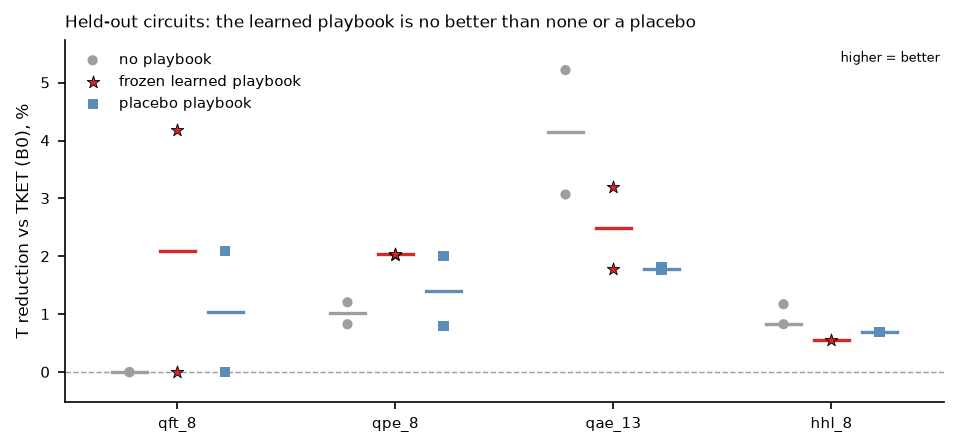

points = valid runs (2 seeds); bars = mean over paired runs; invalid runs omitted


In [15]:
import matplotlib.pyplot as plt
arm_style = {"none": ("no playbook", "#9e9e9e", "o"), "learned": ("frozen learned playbook", "#d62728", "*"),
             "placebo": ("placebo playbook", "#5b8db8", "s")}
circs = list(dict.fromkeys(abl.circuit))
fig, ax = plt.subplots(figsize=(6.4, 3.0))
for k, (a, (lab, col, m)) in enumerate(arm_style.items()):
    sub = abl[(abl.arm == a) & abl.valid]
    xs = [circs.index(c) + (k - 1) * 0.22 for c in sub.circuit]
    ax.scatter(xs, sub.reduction_pct, color=col, marker=m, s=40 if m == "*" else 24, label=lab, zorder=3,
               edgecolor="black" if a == "learned" else "none", linewidth=0.4)
    means = sub[sub.in_paired].groupby("circuit").reduction_pct.mean()
    for c, v in means.items():
        x0 = circs.index(c) + (k - 1) * 0.22
        ax.plot([x0 - 0.08, x0 + 0.08], [v, v], color=col, lw=1.6, zorder=2)
ax.axhline(0, color="#9e9e9e", lw=0.7, ls="--")
ax.set_xticks(range(len(circs))); ax.set_xticklabels(circs)
ax.set_ylabel("T reduction vs TKET (B0), %")
ax.set_title("Held-out circuits: the learned playbook is no better than none or a placebo", loc="left", fontsize=8)
ax.text(0.995, 0.97, "higher = better", transform=ax.transAxes, ha="right", va="top", fontsize=6)
ax.legend(frameon=False, fontsize=7, loc="upper left")
ax.margins(x=0.06, y=0.1); fig.tight_layout(); show_fig(fig)
print("points = valid runs (2 seeds); bars = mean over paired runs; invalid runs omitted")


**Takeaway (computed from the files above).**

In [16]:
ln, lp = PS["learned-none"], PS["learned-placebo"]
both_zero = all(v["boot95"][0] <= 0 <= v["boot95"][1] for v in (ln, lp))
valid_runs = abl[abl.valid]
best_llm = valid_runs.loc[valid_runs.reduction_pct.idxmax()]
n_act = len(act)
display(Markdown("\n".join([
    f"1. **Null result.** learned - none = {ln['mean_pp']:+.2f} pp (95% CI {ln['boot95'][0]:+.2f} to {ln['boot95'][1]:+.2f}, "
    f"sign test p = {ln['sign_test_p']:.2f}); learned - placebo = {lp['mean_pp']:+.2f} pp (CI {lp['boot95'][0]:+.2f} to "
    f"{lp['boot95'][1]:+.2f}, p = {lp['sign_test_p']:.2f}), over {ln['n_pairs']} paired circuit x seed blocks. "
    f"Both CIs contain zero: **{both_zero}**. The placebo arm is as far from 'none' as the learned arm "
    f"(placebo - none = {PS['placebo-none']['mean_pp']:+.2f} pp).",
    f"2. **One generic rule.** Of {len(dev_pb.rules)} rules the reflector proposed on the development circuits, "
    f"{n_act} became active ({', '.join(r.id for r in act)}: track the Pauli frame before deleting a rotation), which largely "
    f"restates what the prompt already provides; so this tests a single generic rule, not a rich playbook.",
    "",
    "**So:** more rules in the prompt is not where the gain is. The next step is to change *what the LLM decides*: let it "
    "choose the strategy and the error-budget allocation (which windows to spend the approximation budget on, which "
    "rotations to fix vs. synthesize), rather than asking it for local window rewrites.",
])))

1. **Null result.** learned - none = +0.38 pp (95% CI -1.21 to +1.93, sign test p = 0.69); learned - placebo = +0.66 pp (CI -0.60 to +1.99, p = 1.00), over 7 paired circuit x seed blocks. Both CIs contain zero: **True**. The placebo arm is as far from 'none' as the learned arm (placebo - none = -0.28 pp).
2. **One generic rule.** Of 28 rules the reflector proposed on the development circuits, 1 became active (R3: track the Pauli frame before deleting a rotation), which largely restates what the prompt already provides; so this tests a single generic rule, not a rich playbook.

**So:** more rules in the prompt is not where the gain is. The next step is to change *what the LLM decides*: let it choose the strategy and the error-budget allocation (which windows to spend the approximation budget on, which rotations to fix vs. synthesize), rather than asking it for local window rewrites.

## 7. Stage-1 results: LLM loop vs B0 and the bar

From `results/window_runs/stage1/stage1_results.csv`. **bar** = best valid of B0, B1, B2, B3g.
Some ε = 1e-5 runs were dropped for token budget (blank "ours"; listed below).


not run (token budget): qft_8 ε=1e-5, heisenberg_6 ε=1e-5, tfim_6 ε=1e-5, hubbard_8 ε=1e-5, qml_13 ε=1e-5


B0    bar   bar arm ours (LLM loop) ours vs B0 % ours vs bar % LLM calls
circuit      ε                                                                                
qft_8        1e-3   2391   1577        B1            2341         -2.1          48.4        44
             1e-5   3299   2219        B1                                                     
qpe_8        1e-3  14761   8020       B3g           14225         -3.6          77.4        44
             1e-5  19853  10391       B3g           19471         -1.9          87.4        44
qae_13       1e-3   7821   4527        B1            7679         -1.8          69.6        44
             1e-5  11017   6361        B1           11017          0.0          73.2        44
heisenberg_6 1e-3   8200   8200  B0=B1=B2            8200          0.0           0.0        44
             1e-5  11200  11200  B0=B1=B2                                                     
tfim_6       1e-3   8560   8560  B0=B1=B2            8560          0.0           0.0        44
             1e-5  11840  11840  B0=B1=B2                                                     
hubbard_8    1e-3   4312   4312  B0=B1=B2            4312          0.0           0.0        44
             1e-5   6000   6000  B0=B1=B2                                                     
qml_13       1e-3   6326   6326  B0=B1=B2            6326          0.0           0.0        44
             1e-5   8716   8716  B0=B1=B2                                                     
hhl_8        1e-3  35450  19443       B3g           34797         -1.8          79.0        44
             1e-5  47228  25043       B3g           46280         -2.0          84.8        44

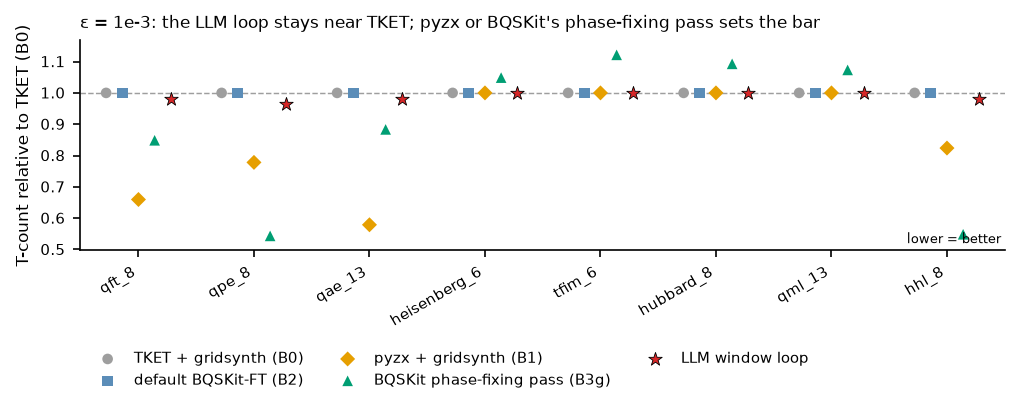

In [17]:
res = pd.read_csv(S1 / "stage1_results.csv")
res["ε"] = res.eps.map({1e-3: "1e-3", 1e-5: "1e-5"})
cols = {"circuit": "circuit", "ε": "ε", "B0": "B0", "bar": "bar", "bar_arm": "bar arm", "ours_T": "ours (LLM loop)",
        "ours_vs_B0_pct": "ours vs B0 %", "ours_vs_bar_pct": "ours vs bar %",
        "llm_calls": "LLM calls"}
t6 = res[list(cols)].rename(columns=cols)
t6["ours (LLM loop)"] = t6["ours (LLM loop)"].map(lambda x: "" if pd.isna(x) else f"{int(x)}")
t6["LLM calls"] = t6["LLM calls"].map(lambda x: "" if pd.isna(x) else f"{int(x)}")
print("not run (token budget):", ", ".join(f"{c} ε={e}" for c, e in zip(res[res.run != "yes"].circuit, res[res.run != "yes"]["ε"])))
display(t6.set_index(["circuit", "ε"]).fillna(""))
import matplotlib.pyplot as plt, numpy as np
d3 = res[res.eps == 1e-3].set_index("circuit").loc[CIRCS]
ser = [("B0", "TKET + gridsynth (B0)", "#9e9e9e", "o"), ("B2", "default BQSKit-FT (B2)", "#5b8db8", "s"),
       ("B1", "pyzx + gridsynth (B1)", "#e69f00", "D"), ("B3g", "BQSKit phase-fixing pass (B3g)", "#009e73", "^"),
       ("ours_T", "LLM window loop", "#d62728", "*")]
xx = np.arange(len(CIRCS)); off = np.linspace(-0.28, 0.28, len(ser))
fig, ax = plt.subplots(figsize=(6.8, 3.2))
for (c, lab, col, m), o in zip(ser, off):
    ax.scatter(xx + o, d3[c] / d3.B0, color=col, marker=m, s=46 if m == "*" else 26, label=lab, zorder=3,
               edgecolor="black" if c == "ours_T" else "none", linewidth=0.4)
ax.axhline(1.0, color="#9e9e9e", lw=0.7, ls="--")
ax.set_xticks(xx); ax.set_xticklabels(CIRCS, rotation=30, ha="right")
ax.set_ylabel("T-count relative to TKET (B0)")
ax.set_title("ε = 1e-3: the LLM loop stays near TKET; pyzx or BQSKit's phase-fixing pass sets the bar", loc="left", fontsize=8)
ax.text(0.995, 0.02, "lower = better", transform=ax.transAxes, ha="right", va="bottom", fontsize=6)
ax.legend(frameon=False, ncol=3, fontsize=7, loc="upper left", bbox_to_anchor=(0, -0.42))
ax.margins(x=0.03, y=0.08); fig.tight_layout(); show_fig(fig)

**Takeaway (computed from the table above).**

In [18]:
ran = res[res.run == "yes"]
gain = ran[ran.ours_vs_B0_pct < 0]
e3 = gain[gain.eps == 1e-3]
tot_tok = int(ran.input_tokens.sum() + ran.output_tokens.sum())
none = ran[(ran.accepted_fix + ran.accepted_window) == 0]
flat_rows = none[(none.ours_T == none.B0) & (none.B0 == none.bar)]
display(Markdown(f'''
* **Preliminary**: {res.circuit.nunique()} small circuits ({res.qubits.min()}–{res.qubits.max()} qubits), one seed,
  {int(ran.proposal_calls.min())}–{int(ran.proposal_calls.max())} proposer calls per run, {len(ran)} runs,
  {tot_tok:,} tokens; playbook learned and measured on the same circuits.
* The LLM loop improves B0 by **{-e3.ours_vs_B0_pct.max():.1f}–{-e3.ours_vs_B0_pct.min():.1f} %** on
  {len(e3)} circuits at ε = 1e-3 ({", ".join(e3.circuit)}); at 1e-5 by {", ".join(f"{-x:.1f} %" for x in gain[gain.eps == 1e-5].ours_vs_B0_pct)}
  on {", ".join(gain[gain.eps == 1e-5].circuit)}. No rewrite was accepted on {", ".join(f"{c} ({e})" for c, e in zip(none.circuit, none["ε"]))};
  on {", ".join(sorted(set(flat_rows.circuit)))} that leaves ours = B0 = bar.
* It is **far from the bar** (pyzx B1 or B3g): {gain.ours_vs_bar_pct.min():.0f}–{gain.ours_vs_bar_pct.max():.0f} % above it where it improves.
  Window-local rewrites cannot do what
  global ZX simplification or DPF with re-instantiation do.
'''))


* **Preliminary**: 8 small circuits (6–13 qubits), one seed,
  40–44 proposer calls per run, 11 runs,
  1,624,660 tokens; playbook learned and measured on the same circuits.
* The LLM loop improves B0 by **1.8–3.6 %** on
  4 circuits at ε = 1e-3 (qft_8, qpe_8, qae_13, hhl_8); at 1e-5 by 1.9 %, 2.0 %
  on qpe_8, hhl_8. No rewrite was accepted on qae_13 (1e-5), heisenberg_6 (1e-3), tfim_6 (1e-3), hubbard_8 (1e-3), qml_13 (1e-3);
  on heisenberg_6, hubbard_8, qml_13, tfim_6 that leaves ours = B0 = bar.
* It is **far from the bar** (pyzx B1 or B3g): 48–87 % above it where it improves.
  Window-local rewrites cannot do what
  global ZX simplification or DPF with re-instantiation do.


**Next steps.** (1) Start the loop from the stronger inputs (pyzx B1 output, the B3g pre-gridsynth circuit) so the
LLM works on the residual. (2) Freeze the stage-1 playbook and evaluate it on held-out circuits before reading anything
into its rules (done with a fresh development playbook in section 6: null result). (3) Phase kickback (B4) remains out of
scope until the `pkac` branch is integrated.


In [19]:
print(f"notebook runtime: {time.time() - T0:.1f} s (no network, no LLM calls)")

notebook runtime: 38.4 s (no network, no LLM calls)
